In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)

In [3]:
df = pd.read_csv("credit_score_fraud_detection_200_rows.csv")
df

,ApplicantID,CreditScore,ApplicantIncome,LoanAmount,LoanTermMonths,EmploymentYears,ExistingLoans,Dependents,PropertyAreaCode,DebtToIncomeRatio,FraudLabel
0,APP0111,584,55817,254715,36,4.4,1,2,1,0.437,0
1,APP0079,657,81130,563352,36,11.5,0,0,2,0.579,1
2,APP0065,711,48224,204262,48,7.5,2,0,3,0.417,0
3,APP0077,655,119658,501094,60,6.3,2,1,3,0.425,0
4,APP0147,637,55284,23035,36,3.6,4,0,1,0.118,0
...,...,...,...,...,...,...,...,...,...,...,...
195,APP0086,568,119926,471176,36,7.6,0,3,3,0.327,0
196,APP0198,696,37732,142451,6,7.9,2,4,2,0.414,0
197,APP0055,721,94005,304789,36,5.2,4,2,3,0.454,0
198,APP0083,618,47315,95345,6,12.7,5,2,1,0.248,0


In [6]:
df.head()

,ApplicantID,CreditScore,ApplicantIncome,LoanAmount,LoanTermMonths,EmploymentYears,ExistingLoans,Dependents,PropertyAreaCode,DebtToIncomeRatio,FraudLabel
0,APP0111,584,55817,254715,36,4.4,1,2,1,0.437,0
1,APP0079,657,81130,563352,36,11.5,0,0,2,0.579,1
2,APP0065,711,48224,204262,48,7.5,2,0,3,0.417,0
3,APP0077,655,119658,501094,60,6.3,2,1,3,0.425,0
4,APP0147,637,55284,23035,36,3.6,4,0,1,0.118,0


In [7]:
df.shape

(200, 11)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ApplicantID        200 non-null    str    
 1   CreditScore        200 non-null    int64  
 2   ApplicantIncome    200 non-null    int64  
 3   LoanAmount         200 non-null    int64  
 4   LoanTermMonths     200 non-null    int64  
 5   EmploymentYears    200 non-null    float64
 6   ExistingLoans      200 non-null    int64  
 7   Dependents         200 non-null    int64  
 8   PropertyAreaCode   200 non-null    int64  
 9   DebtToIncomeRatio  200 non-null    float64
 10  FraudLabel         200 non-null    int64  
dtypes: float64(2), int64(8), str(1)
memory usage: 17.3 KB


In [9]:
df.isnull().sum()

ApplicantID          0
CreditScore          0
ApplicantIncome      0
LoanAmount           0
LoanTermMonths       0
EmploymentYears      0
ExistingLoans        0
Dependents           0
PropertyAreaCode     0
DebtToIncomeRatio    0
FraudLabel           0
dtype: int64

In [11]:
df.describe()

,CreditScore,ApplicantIncome,LoanAmount,LoanTermMonths,EmploymentYears,ExistingLoans,Dependents,PropertyAreaCode,DebtToIncomeRatio,FraudLabel
count,200.000000,200.00000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,662.365000,61530.34000,192999.105000,34.500000,6.579000,1.800000,1.615000,1.925000,0.318180,0.120000
std,83.260032,29840.54453,157627.093598,16.957233,4.185253,1.556313,1.472282,0.776136,0.164984,0.325777
min,358.000000,17328.00000,9724.000000,6.000000,0.100000,0.000000,0.000000,1.000000,0.041000,0.000000
25%,625.000000,40446.00000,81772.750000,24.000000,3.400000,1.000000,0.000000,1.000000,0.187000,0.000000
50%,670.500000,56517.00000,140624.000000,36.000000,6.050000,1.000000,1.000000,2.000000,0.292500,0.000000
75%,710.250000,75677.00000,262058.750000,48.000000,8.425000,3.000000,3.000000,3.000000,0.422000,0.000000
max,850.000000,203286.00000,884566.000000,60.000000,20.500000,5.000000,5.000000,3.000000,0.816000,1.000000


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:

df["FraudLabel"].value_counts()

FraudLabel
0    176
1     24
Name: count, dtype: int64

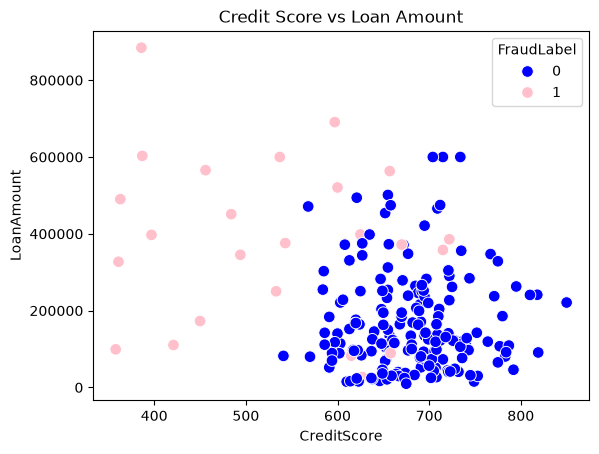

In [69]:
sns.scatterplot(
    data=df,
    x="CreditScore",
    y="LoanAmount",
    hue="FraudLabel",
    palette={0: "blue", 1: "pink"},
    s=70
)

plt.title("Credit Score vs Loan Amount")
plt.show()

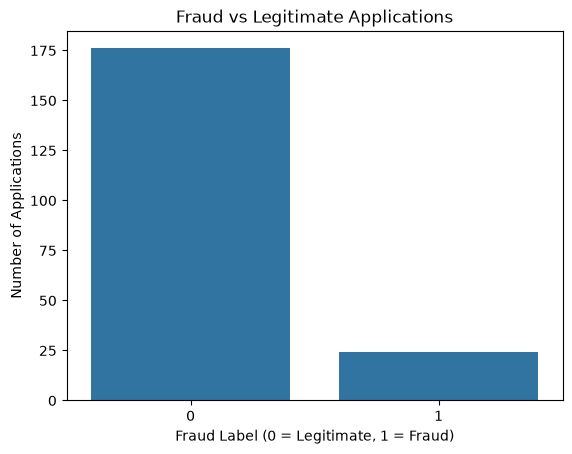

In [14]:
sns.countplot(data=df, x="FraudLabel")
plt.title("Fraud vs Legitimate Applications")
plt.xlabel("Fraud Label (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Applications")
plt.show()

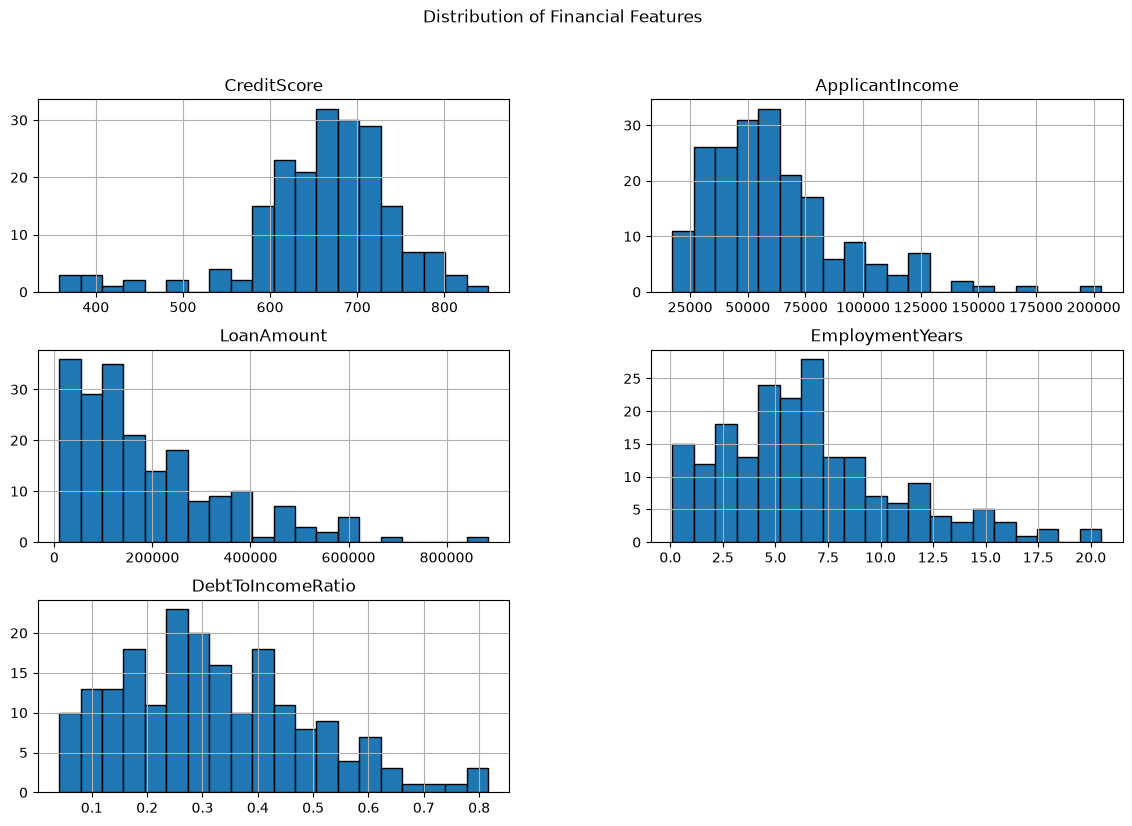

In [71]:
df[["CreditScore", "ApplicantIncome", "LoanAmount",
    "EmploymentYears", "DebtToIncomeRatio"]].hist(
    figsize=(14, 9), bins=20, edgecolor="black"
)

plt.suptitle("Distribution of Financial Features")
plt.show()

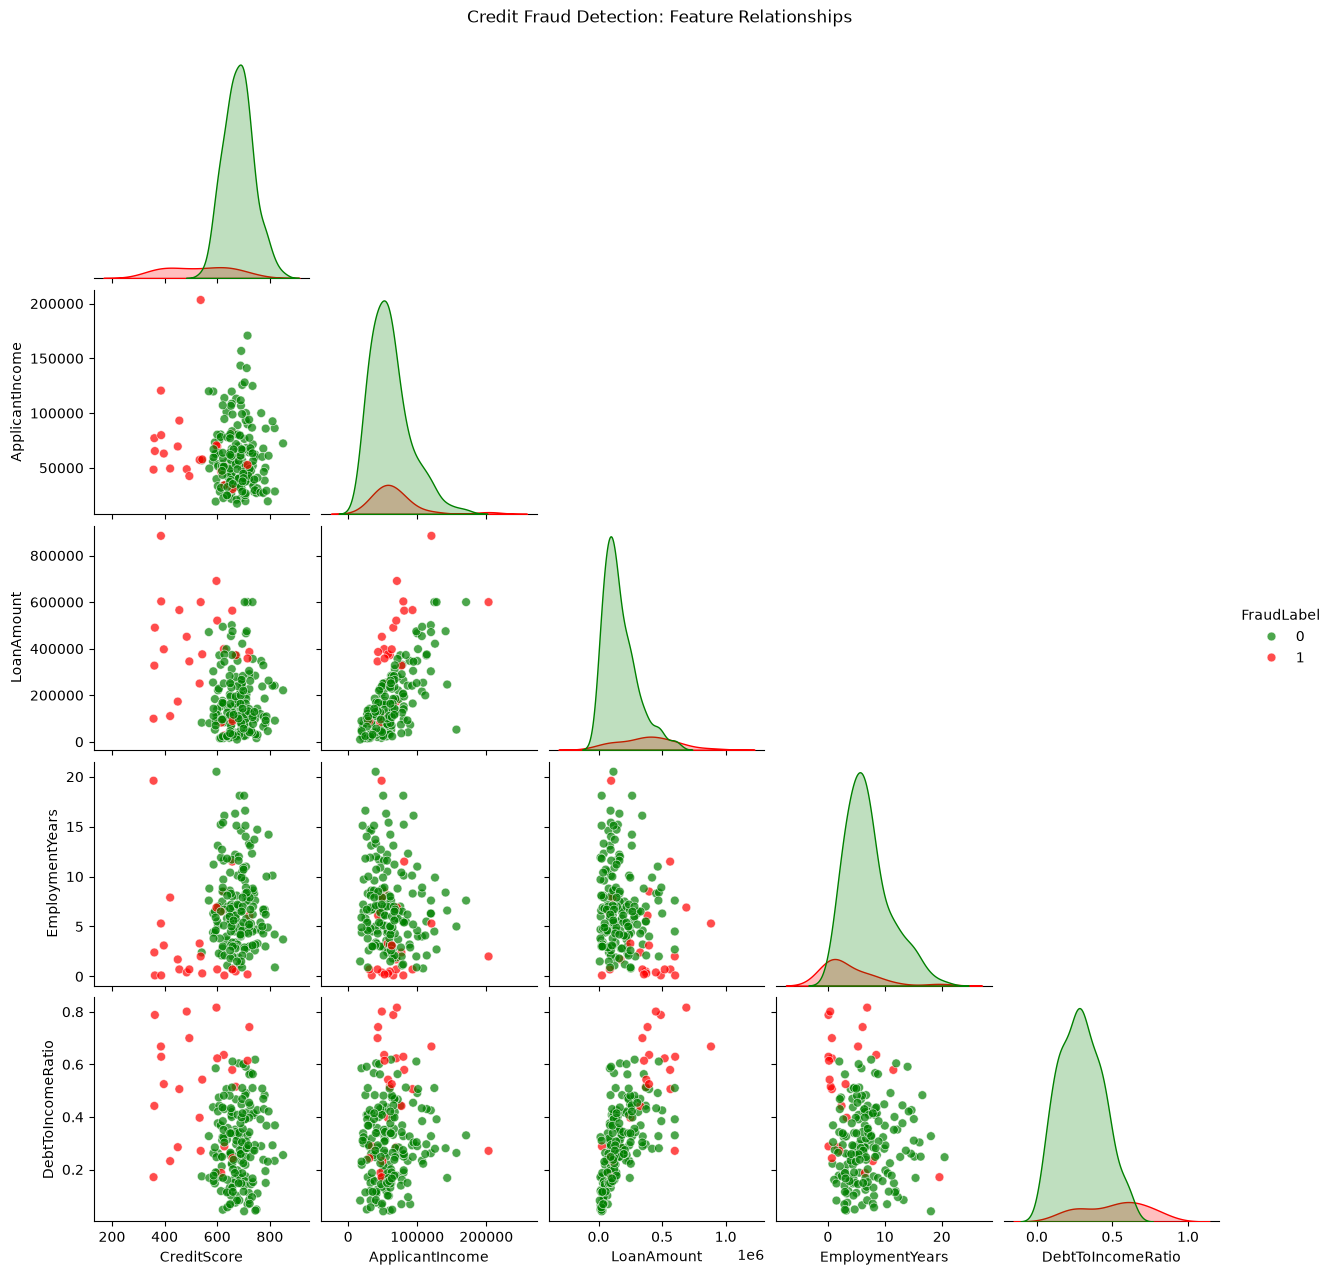

In [65]:
sns.pairplot(
    data=df,
    vars=["CreditScore","ApplicantIncome","LoanAmount","EmploymentYears","DebtToIncomeRatio"],
    hue="FraudLabel",
    palette={0: "green", 1: "red"},
    diag_kind="kde",
    corner=True,
    plot_kws={"alpha": 0.7, "s": 40}
)

plt.suptitle("Credit Fraud Detection: Feature Relationships",y=1.02)
plt.show()

In [16]:
X = df.drop(["ApplicantID", "FraudLabel"], axis=1)
y = df["FraudLabel"]

In [18]:
print(X.shape)
print(y.shape)

(200, 9)
(200,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [20]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 9)
Testing data: (40, 9)


In [21]:
scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)


In [31]:
model = LogisticRegression()
model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [34]:
model.fit(X_train_sc, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [35]:
y_pred = model.predict(X_test_sc)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Actual values:
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 1]

Predicted values:
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0
 0 0 1]


In [36]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 95.0 %


In [37]:
print(classification_report(y_test,y_pred,target_names=["Legitimate", "Fraud"]))

              precision    recall  f1-score   support

  Legitimate       0.95      1.00      0.97        35
       Fraud       1.00      0.60      0.75         5

    accuracy                           0.95        40
   macro avg       0.97      0.80      0.86        40
weighted avg       0.95      0.95      0.94        40



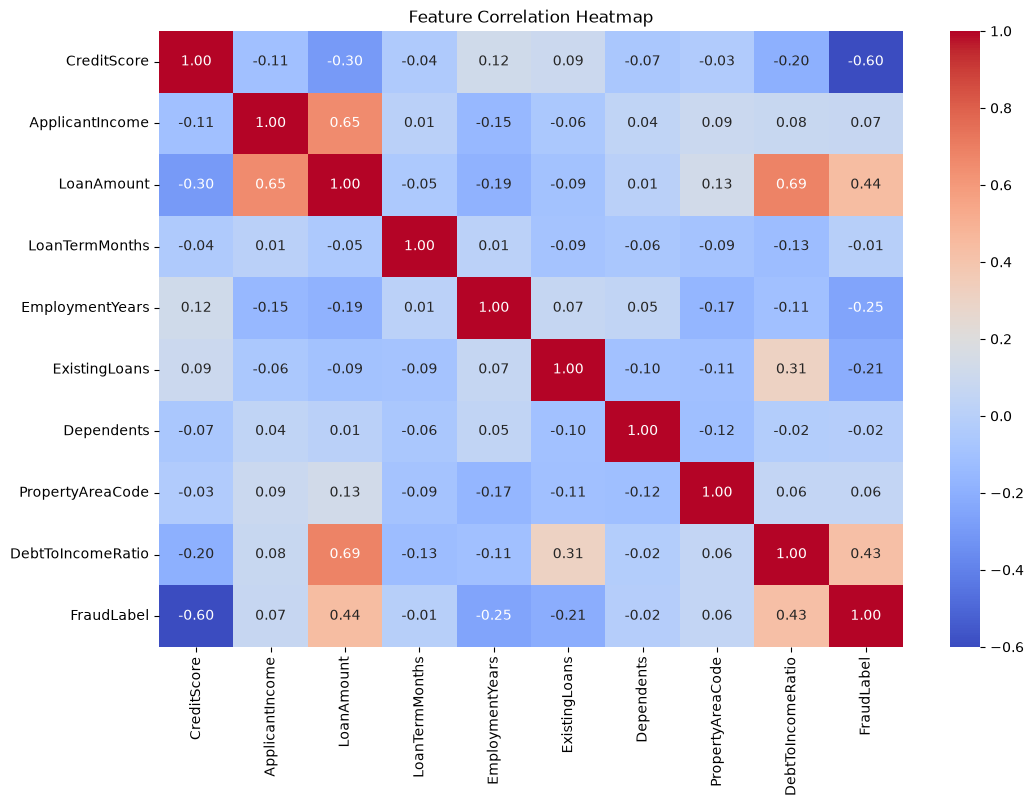

In [74]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=["ApplicantID"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [43]:
credit_score = int(input("Enter Credit Score (300-850): "))
income = float(input("Enter Applicant Income: "))
loan_amount = float(input("Enter Loan Amount: "))
loan_term = int(input("Enter Loan Term in Months: "))
employment_years = float(input("Enter Employment Years: "))
existing_loans = int(input("Enter Number of Existing Loans: "))
dependents = int(input("Enter Number of Dependents: "))
property_area = int(input("Enter Property Area Code (1, 2, or 3): "))
debt_ratio = float(input("Enter Debt-to-Income Ratio: "))

user_data = pd.DataFrame([[
    credit_score,
    income,
    loan_amount,
    loan_term,
    employment_years,
    existing_loans,
    dependents,
    property_area,
    debt_ratio
]], columns=X.columns)

user_data_sc = scaler.transform(user_data)

prediction = model.predict(user_data_sc)[0]

print("\n--- Fraud Detection Result ---")

if prediction == 1:
    print(" Potential Fraud Detected")
else:
    print(" No Fraud Detected by Model")


Enter Credit Score (300-850):  70
Enter Applicant Income:  889
Enter Loan Amount:  899
Enter Loan Term in Months:  78
Enter Employment Years:  68
Enter Number of Existing Loans:  5
Enter Number of Dependents:  5
Enter Property Area Code (1, 2, or 3):  7
Enter Debt-to-Income Ratio:  4



--- Fraud Detection Result ---
 Potential Fraud Detected


In [52]:
compare_df = pd.DataFrame({
    "Actual Y": y_test.values,
    "Model Predicted Value": y_pred
})

compare_df

,Actual Y,Model Predicted Value
0,0,0
1,0,0
2,0,0
3,0,0
4,1,1
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [53]:
MAE=(compare_df["Actual Y"]-compare_df["Model Predicted Value"]).abs().mean()
print("Mean Absolute Error",round(MAE,2))

Mean Absolute Error 0.05


In [54]:
MSE=((compare_df["Actual Y"]-compare_df["Model Predicted Value"])**2).abs().mean()
print("Mean Square Error",round(MSE,2))

Mean Square Error 0.05


In [56]:
import math
RMSE=math.sqrt(MSE)
print("Root mean Squared Error",round(RMSE,2))

Root mean Squared Error 0.22
